In [45]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr   
import rioxarray as rioaxr
import contextily as ctx


In [3]:
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')

In [9]:
eji_gdb = gpd.read_file('data/EJI_2024_California/EJI_2024_California.gdb')

In [4]:
palisades = gpd.read_file(os.path.join('data', 
                                    'Palisades_Perimieter_20250121', 
                                    'Palisades_Perimieter_20250121.shp'))


eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121', 
                                    'Eaton_Perimeter_20250121.shp'))


In [22]:
palisades

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


<Axes: >

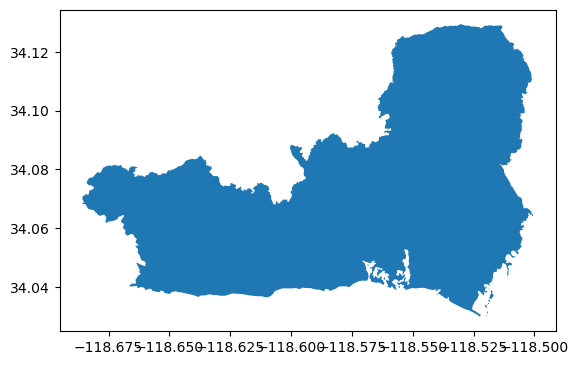

In [17]:
palisades.plot()

<Axes: >

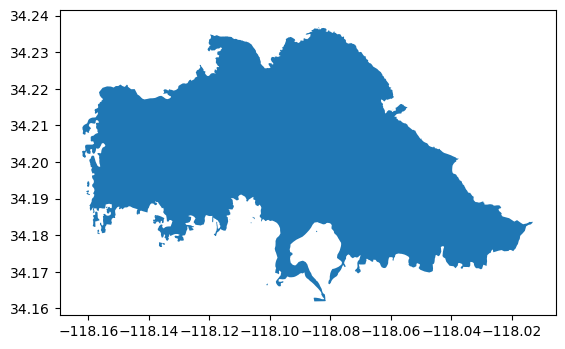

In [18]:
eaton.plot()

In [31]:
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)
eji_gdb = eji_gdb.to_crs(palisades.crs)

Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269


In [36]:
palisades_eji = gpd.sjoin(eji_gdb, palisades, how = 'inner', predicate='intersects')
print("census tracts intersecting with Palisades fire: {len(palisades_eji)}")

census tracts intersecting with Palisades fire: {len(palisades_eji)}


In [3]:
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

pd.set_option('display.max_colwidth', 120)
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


In [ ]:
eaton_eji = gpd.sjoin(eji_gdb, eaton, how = 'inner', predicate='intersects')

## 4. Visualize fire perimeters with a basemap

/var/folders/qq/__84s6mx7ts00l_9thlrm_z40000gp/T/ipykernel_40129/379714274.py:10: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


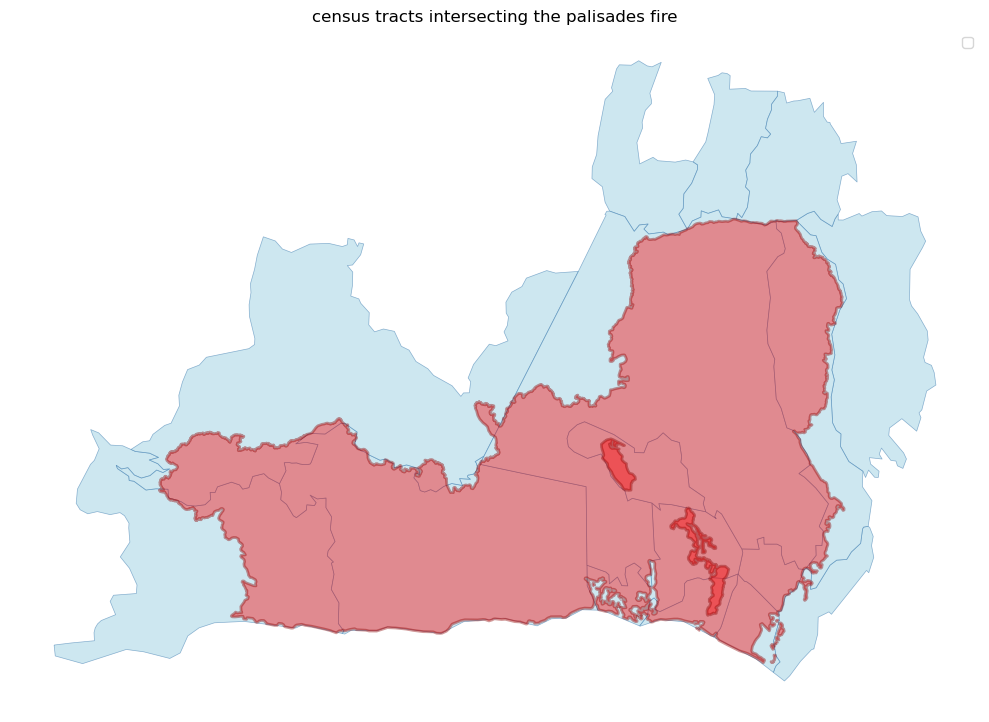

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

palisades_eji.plot(ax=ax, color = 'lightblue', edgecolor = 'steelblue', linewidth = 0.5, alpha = 0.6, label = 'census tracts')
palisades.plot(ax=ax, color='red', alpha =0.4, edgecolor='darkred', linewidth = 2, label='palisades perimeter')
# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx
ax.set_title('census tracts intersecting the palisades fire')
ax.legend()
ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
eaton_eji = gpd.sjoin(eji_gdb, eaton, how = 'inner', predicate='intersects')

/var/folders/qq/__84s6mx7ts00l_9thlrm_z40000gp/T/ipykernel_40129/53045617.py:10: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


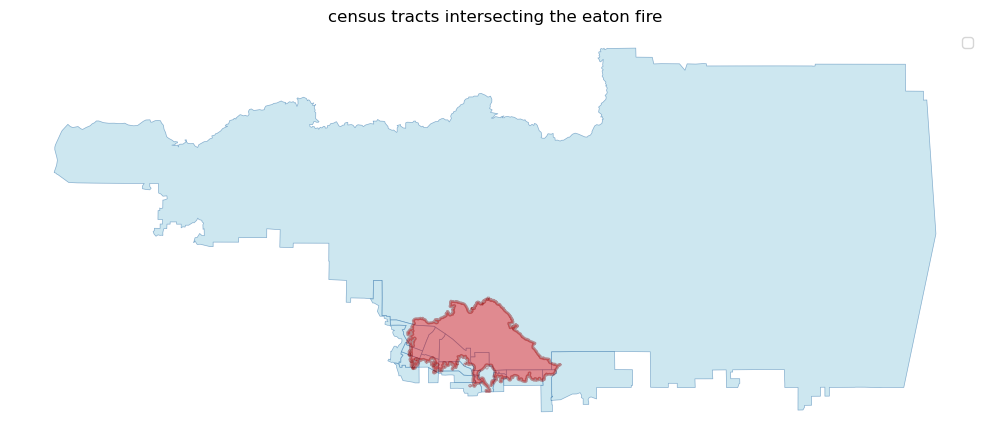

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

eaton_eji.plot(ax=ax, color = 'lightblue', edgecolor = 'steelblue', linewidth = 0.5, alpha = 0.6, label = 'census tracts')
eaton.plot(ax=ax, color='red', alpha =0.4, edgecolor='darkred', linewidth = 2, label='palisades perimeter')
# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them

ax.set_title('census tracts intersecting the eaton fire')
ax.legend()
ax.axis('off')

plt.tight_layout()
plt.show()